# MROOT: final control and MixUp/CutMix training

    I compared two EVA-02 Base runs using the same initial weights and reviewed data.
    The candidate added a batch-level MixUp/CutMix policy to the reference recipe.

    The code is organised from the exported experiment source. Augmentation, sampling, optimizer,
    learning-rate schedule, loss, and checkpoint selection follow the saved recipe. Setup and logging
    are simplified, and the original source is included in `evidence/original_training_helpers.py`.
    Tables and images show saved historical results. **Training is disabled by default.**


## Load the saved settings and data lists


In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import Image as OutputImage, display

ROOT = next(
    (
        folder for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "notebooks/evidence").is_dir()
        and (folder / "class_mapping.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the complete repository checkout.")

EVIDENCE = ROOT / "notebooks/evidence"


def read_report(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8"))


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


,Setting,Value
0,seed,27182
1,max_epochs,20
2,patience,8
3,effective_batch_size,16
4,head_lr,3.3333333333333335e-05
5,backbone_lr,6.6666666666666675e-06
6,layer_decay,0.8


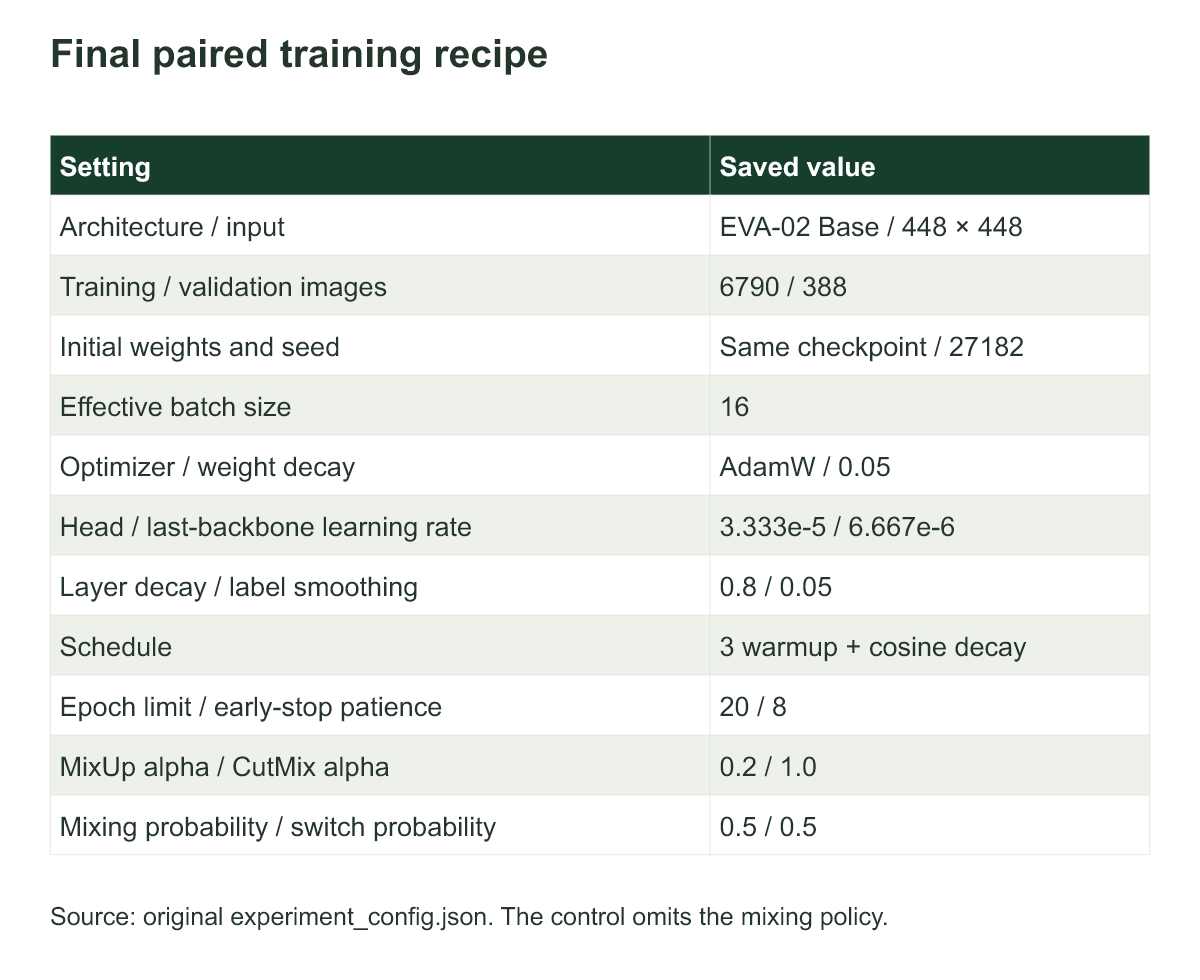

In [2]:
train_manifest = EVIDENCE / "experiment_train.csv"
validation_manifest = EVIDENCE / "experiment_validation.csv"
split_summary = read_report("split_summary.json")

assert file_sha256(train_manifest) == split_summary["train_sha256"]
assert file_sha256(validation_manifest) == split_summary["validation_sha256"]

train = pd.read_csv(train_manifest)
validation = pd.read_csv(validation_manifest)
mapping = json.loads((ROOT / "class_mapping.json").read_text())
classes = sorted(mapping, key=mapping.get)

assert len(train) == 6790 and len(validation) == 388
assert set(train.label) == set(validation.label) == set(range(39))
assert not set(train.path) & set(validation.path)
assert not set(train.duplicate_group) & set(validation.duplicate_group)
assert all(mapping[row.disease] == row.label for row in train.itertuples())
assert all(mapping[row.disease] == row.label for row in validation.itertuples())

settings = read_report("final_settings.json")
saved_config = read_report("control/experiment_config.json")
saved_results = read_report("PAIRED_TRAINING_RESULTS.json")
mroot_clean_settings = settings

display(pd.DataFrame([
    {"Setting": key, "Value": str(settings[key])}
    for key in [
        "seed", "max_epochs", "patience", "effective_batch_size",
        "head_lr", "backbone_lr", "layer_decay",
    ]
]))
display(OutputImage(filename=str(ROOT / "notebooks/images/training_recipe.png")))


## Optional training setup

    Review mode needs only the small notebook dependencies. Training additionally requires CUDA
    PyTorch, torchvision, timm, and scikit-learn. It uses the **original initial checkpoint** named
    in the saved config, which is not included in GitHub. It will stop if that checkpoint is absent
    or its checksum differs. No substitute starting weights are downloaded.


In [3]:
RUN_TRAINING = False
INITIAL_CHECKPOINT = Path(saved_config["initial_state"])

if RUN_TRAINING:
    import gc
    import random
    import re
    import time
    from datetime import datetime, timezone
    from uuid import uuid4

    import torch
    import torch.nn.functional as F
    import timm
    from sklearn.metrics import average_precision_score
    from timm.data import Mixup
    from torch.utils.data import DataLoader, WeightedRandomSampler
    from torchvision import transforms
    from torchvision.transforms import InterpolationMode
else:
    print("Review mode: no model is loaded and no training is launched.")


Review mode: no model is loaded and no training is launched.


## Images and augmentation

    Training uses random crops, flips, small rotations, color changes, RandAugment, and erasing.
    The ordinary validation transform comes from the saved model configuration.
    A separate padded view keeps the whole image for the final prediction recipe.


In [4]:
class CleanLeafImages:
    def __init__(self, frame, transform, padded_transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.padded_transform = padded_transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as source:
            image = source.convert("RGB")

        normal = self.transform(image)
        if self.padded_transform is not None:
            return normal, self.padded_transform(image), int(row.label)
        return normal, int(row.label)


class CleanWholeImagePad:
    def __init__(self, size, mean):
        self.size = size
        self.fill = tuple(round(value * 255) for value in mean)

    def __call__(self, image):
        width, height = image.size
        scale = self.size / max(width, height)
        width = max(1, round(width * scale))
        height = max(1, round(height * scale))
        resized = image.resize((width, height), Image.Resampling.BICUBIC)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        canvas.paste(resized, ((self.size - width) // 2, (self.size - height) // 2))
        return canvas


In [5]:
def clean_image_transforms(config):
    training = transforms.Compose([
        transforms.RandomResizedCrop(
            448, scale=(0.8, 1.0), ratio=(0.9, 1.1),
            interpolation=InterpolationMode.BICUBIC,
        ),
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomVerticalFlip(0.1),
        transforms.RandomRotation(10, interpolation=InterpolationMode.BICUBIC),
        transforms.ColorJitter(0.15, 0.15, 0.10, 0.02),
        transforms.RandAugment(num_ops=2, magnitude=7),
        transforms.ToTensor(),
        transforms.Normalize(config["mean"], config["std"]),
        transforms.RandomErasing(p=0.15, scale=(0.02, 0.08)),
    ])
    validation = timm.data.create_transform(**config, is_training=False)
    padded = transforms.Compose([
        CleanWholeImagePad(448, config["mean"]),
        transforms.ToTensor(),
        transforms.Normalize(config["mean"], config["std"]),
    ])
    return training, validation, padded


## Reproducible sampling

    Both runs draw 6,790 training examples per epoch with replacement. Inverse class-frequency weights
    give rare classes more opportunities to appear. The seed and worker setup match the saved run.


In [6]:
def seed_clean_run(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def clean_worker_seed(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


In [7]:
def create_loaders(train, validation, data_config, micro_batch):
    training_transform, validation_transform, padded_transform = (
        clean_image_transforms(data_config)
    )
    counts = train.groupby("label").size().reindex(range(39)).to_numpy()
    sample_weights = torch.as_tensor(
        1.0 / counts[train.label.to_numpy()], dtype=torch.double
    )
    sampler_generator = torch.Generator().manual_seed(settings["seed"])
    loader_generator = torch.Generator().manual_seed(settings["seed"] + 1)
    sampler = WeightedRandomSampler(
        sample_weights,
        num_samples=len(train),
        replacement=True,
        generator=sampler_generator,
    )
    train_loader = DataLoader(
        CleanLeafImages(train, training_transform),
        batch_size=micro_batch,
        sampler=sampler,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True,
        worker_init_fn=clean_worker_seed,
        generator=loader_generator,
    )
    validation_loader = DataLoader(
        CleanLeafImages(validation, validation_transform),
        batch_size=micro_batch,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True,
    )
    view_loader = DataLoader(
        CleanLeafImages(validation, validation_transform, padded_transform),
        batch_size=micro_batch,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )
    return train_loader, validation_loader, view_loader


## Optimizer and learning rates

    AdamW uses layer-wise learning-rate decay. Early layers change more cautiously than the last
    backbone layers and classifier. The schedule has three warmup epochs followed by cosine decay.


In [8]:
def clean_optimizer(model, output_dir):
    settings = mroot_clean_settings
    head_parameters = {id(parameter) for parameter in model.get_classifier().parameters()}
    depth = len(model.blocks)
    groups = {}
    records = []

    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue

        if id(parameter) in head_parameters:
            layer = "head"
            learning_rate = settings["head_lr"]
        else:
            match = re.match(r"blocks\.(\d+)\.", name)
            if match:
                layer_id = int(match.group(1)) + 1
            elif name.startswith(("norm.", "fc_norm.")):
                layer_id = depth
            else:
                layer_id = 0
            layer = str(layer_id)
            learning_rate = settings["backbone_lr"] * settings["layer_decay"] ** (depth - layer_id)

        key = (layer, learning_rate)
        if key not in groups:
            groups[key] = {
                "params": [],
                "lr": learning_rate,
                "weight_decay": settings["weight_decay"],
            }
        groups[key]["params"].append(parameter)
        records.append({
            "name": name,
            "layer": layer,
            "max_lr": learning_rate,
            "weight_decay": settings["weight_decay"],
            "parameters": parameter.numel(),
        })

    parameters = [parameter for group in groups.values() for parameter in group["params"]]
    assert len({id(parameter) for parameter in parameters}) == len(parameters)
    assert sum(parameter.numel() for parameter in parameters) == sum(
        parameter.numel() for parameter in model.parameters()
    )

    pd.DataFrame(records).to_csv(output_dir / "parameter_lr_groups.csv", index=False)
    optimizer = torch.optim.AdamW(list(groups.values()), weight_decay=settings["weight_decay"])
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=3)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=settings["max_epochs"] - 3, eta_min=settings["minimum_lr"]
    )
    scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer, [warmup, cosine], milestones=[3]
    )
    return optimizer, scheduler


## MixUp/CutMix and loss

    The control uses label-smoothed cross-entropy. The candidate uses mixed soft targets.
    Mixing activates with probability 0.5. When active, the policy selects MixUp or CutMix at batch level.


In [9]:
def create_mixer(use_mixing):
    if not use_mixing:
        return None
    return Mixup(
        mixup_alpha=settings["mixup_alpha"],
        cutmix_alpha=settings["cutmix_alpha"],
        prob=settings["mix_probability"],
        switch_prob=settings["cutmix_switch_probability"],
        mode="batch",
        label_smoothing=settings["label_smoothing"],
        num_classes=39,
    )


## One training epoch

    FP16 autocast and gradient accumulation give an effective batch size of 16.
    The loss is calculated in float32, gradients are clipped, and non-finite updates trigger AMP backoff.


In [10]:
def train_one_epoch(
    runner, model, loader, optimizer, scaler, mixer, device, overflow_count
):
    runner.train()
    optimizer.zero_grad(set_to_none=True)
    micro_batch = loader.batch_size
    accumulation = settings["effective_batch_size"] // micro_batch
    loss_total = 0.0
    seen = 0
    successful_updates = 0

    for step, (images, labels) in enumerate(loader, 1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        batch_size = len(labels)
        group_start = ((step - 1) // accumulation) * accumulation * micro_batch
        group_size = min(
            settings["effective_batch_size"], len(loader.dataset) - group_start
        )

        soft_targets = None
        if mixer is not None:
            images, soft_targets = mixer(images, labels)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = runner(images)

        if soft_targets is None:
            loss = F.cross_entropy(
                logits.float(), labels, label_smoothing=settings["label_smoothing"]
            )
        else:
            loss = -(soft_targets * F.log_softmax(logits.float(), dim=1)).sum(1).mean()

        assert torch.isfinite(loss), "Non-finite training loss."
        # Վերջին փոքր խմբի դեպքում էլ պահում ենք ճիշտ կշռված միջինը։
        scaler.scale(loss * batch_size / group_size).backward()
        loss_total += float(loss.item()) * batch_size
        seen += batch_size

        if step % accumulation == 0 or step == len(loader):
            scaler.unscale_(optimizer)
            gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            if torch.isfinite(gradient_norm):
                successful_updates += 1
            else:
                overflow_count += 1
                assert overflow_count <= 50, "Too many AMP overflows."
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

    assert seen == len(loader.dataset)
    return loss_total / seen, successful_updates, overflow_count


## Validation and metrics

    Every epoch uses normal-view validation macro mAP for checkpoint selection. Top-1 and Top-5 are
    also recorded. Three-view inference is checked only after selecting the best checkpoint.


In [11]:
def predict_clean_validation(runner, loader, device, fixed_tta=False):
    runner.eval()
    predictions = []
    labels = []

    with torch.inference_mode():
        for batch in loader:
            if fixed_tta:
                normal, padded, target = batch
                padded = padded.to(device, non_blocking=True)
            else:
                normal, target = batch

            normal = normal.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                normal_logits = runner(normal)
                if fixed_tta:
                    flip_logits = runner(torch.flip(normal, dims=[3]))
                    pad_logits = runner(padded)

            probability = normal_logits.float().softmax(1)
            if fixed_tta:
                probability = (
                    0.75 * (probability + flip_logits.float().softmax(1)) / 2
                    + 0.25 * pad_logits.float().softmax(1)
                )
            predictions.append(probability.cpu().numpy())
            labels.append(target.numpy())

    return np.concatenate(predictions), np.concatenate(labels)


def clean_prediction_metrics(labels, probabilities):
    assert probabilities.shape == (len(labels), 39)
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(1), 1, atol=1e-5)
    ranks = (np.argsort(-probabilities, axis=1) == labels[:, None]).argmax(1) + 1
    return {
        "macro_map": float(average_precision_score(np.eye(39)[labels], probabilities, average="macro")),
        "top1": float((probabilities.argmax(1) == labels).mean()),
        "top5": float((ranks <= 5).mean()),
        "images": len(labels),
    }


## Save the best checkpoint

    Each improved validation mAP gets a new checkpoint filename. Class order and preprocessing
    settings are saved with the weights.


In [12]:
def save_best_checkpoint(model, destination, epoch, score, config):
    weights = {
        name: value.detach().cpu().clone()
        for name, value in model.state_dict().items()
    }
    with destination.open("xb") as handle:
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": weights,
                "model_name": config["architecture"],
                "classes": config["classes"],
                "class_to_idx": config["class_to_idx"],
                "data_cfg": config["data_cfg"],
                "seed": settings["seed"],
                "val_map": score["macro_map"],
                "val_acc": score["top1"],
                "config": config,
            },
            handle,
        )


## Complete one run

    This connects the same sampling, mixing, gradient accumulation, validation, and early-stopping
    rules. The original per-batch status files and latest-resume checkpoint are omitted here.
    Saved results below come from the original completed experiment, not this refactored function.


In [13]:
def run_training_arm(arm_name, use_mixing, initial_path, run_root):
    output_dir = run_root / arm_name
    output_dir.mkdir(exist_ok=False)
    seed_clean_run(settings["seed"])
    assert torch.cuda.is_available(), "Training requires a CUDA GPU."
    assert file_sha256(initial_path) == saved_config["initial_sha256"]

    device = torch.device("cuda:0")
    gpu_ids = list(range(min(2, torch.cuda.device_count())))
    micro_batch = 8 if len(gpu_ids) == 2 else 4
    architecture = saved_config["architecture"]
    initial = torch.load(initial_path, map_location="cpu", weights_only=False)
    assert initial["class_to_idx"] == mapping
    assert list(initial["classes"]) == classes
    model = timm.create_model(architecture, pretrained=False, num_classes=39)
    model.load_state_dict(initial["model_state_dict"], strict=True)
    data_config = dict(initial["data_cfg"])
    del initial
    model = model.to(device)
    runner = (
        torch.nn.DataParallel(model, device_ids=gpu_ids)
        if len(gpu_ids) > 1
        else model
    )
    train_loader, validation_loader, view_loader = create_loaders(
        train, validation, data_config, micro_batch
    )
    optimizer, scheduler = clean_optimizer(model, output_dir)
    mixer = create_mixer(use_mixing)
    scaler = torch.amp.GradScaler("cuda", init_scale=1024.0)
    config = {
        **saved_config,
        **settings,
        "arm": arm_name,
        "mixed_examples": use_mixing,
        "initial_state": str(initial_path),
        "train_manifest": str(train_manifest),
        "validation_manifest": str(validation_manifest),
        "micro_batch": micro_batch,
        "gradient_accumulation": settings["effective_batch_size"] // micro_batch,
        "gpu_ids": gpu_ids,
        "loss": "Mixed soft-target CE" if use_mixing else "CE with label smoothing 0.05",
        "notebook_refactor": True,
    }
    (output_dir / "experiment_config.json").write_text(json.dumps(config, indent=2))

    history = []
    best_map = -1.0
    best_epoch = None
    best_path = None
    stale_epochs = 0
    overflow_count = 0
    stop_reason = "epoch_limit"
    started = time.perf_counter()
    seed_clean_run(settings["seed"])

    try:
        for epoch in range(1, settings["max_epochs"] + 1):
            elapsed = time.perf_counter() - started
            last_duration = history[-1]["epoch_seconds"] if history else 0
            if history and elapsed + last_duration > settings["hours_per_arm"] * 3600:
                stop_reason = "time_limit"
                break

            epoch_started = time.perf_counter()
            learning_rate = max(group["lr"] for group in optimizer.param_groups)
            train_loss, updates, overflow_count = train_one_epoch(
                runner, model, train_loader, optimizer, scaler, mixer,
                device, overflow_count,
            )
            probabilities, labels = predict_clean_validation(
                runner, validation_loader, device
            )
            assert np.array_equal(labels, validation.label.to_numpy())
            score = clean_prediction_metrics(labels, probabilities)
            history.append(
                {
                    "epoch": epoch,
                    "train_loss": train_loss,
                    "val_macro_map": score["macro_map"],
                    "val_top1": score["top1"],
                    "val_top5": score["top5"],
                    "successful_updates": updates,
                    "amp_overflows_total": overflow_count,
                    "max_lr": learning_rate,
                    "epoch_seconds": time.perf_counter() - epoch_started,
                }
            )
            pd.DataFrame(history).to_csv(output_dir / "training_history.csv", index=False)

            # Checkpoint-ն ընտրում ենք միայն validation macro mAP-ով։
            if score["macro_map"] > best_map + 1e-8:
                best_map = score["macro_map"]
                best_epoch = epoch
                stale_epochs = 0
                best_path = output_dir / (
                    f"{arm_name}_best_epoch{epoch:02d}_map{best_map:.6f}.pth"
                )
                save_best_checkpoint(model, best_path, epoch, score, config)
            else:
                stale_epochs += 1

            print(
                f"{arm_name} | epoch {epoch:02d} | "
                f"mAP {score['macro_map']:.6f} | best epoch {best_epoch}"
            )
            scheduler.step()
            if stale_epochs >= settings["patience"]:
                stop_reason = "early_stopping"
                break

        assert best_path is not None
        checkpoint = torch.load(best_path, map_location="cpu", weights_only=False)
        model.load_state_dict(checkpoint["model_state_dict"], strict=True)
        del checkpoint
        normal, labels = predict_clean_validation(runner, validation_loader, device)
        fixed, fixed_labels = predict_clean_validation(
            runner, view_loader, device, fixed_tta=True
        )
        assert np.array_equal(labels, fixed_labels)
        normal_score = clean_prediction_metrics(labels, normal)
        assert abs(normal_score["macro_map"] - best_map) < 1e-7
        np.savez_compressed(
            output_dir / "selected_validation_predictions.npz",
            normal=normal,
            fixed=fixed,
            labels=labels,
            original_rows=validation.original_row.to_numpy(),
            historical_copy_free=validation.historical_copy_free.to_numpy(),
            classes=np.array(classes),
        )
        result = {
            "arm": arm_name,
            "epochs_completed": len(history),
            "best_epoch": best_epoch,
            "checkpoint_path": str(best_path),
            "checkpoint_sha256": file_sha256(best_path),
            "normal": normal_score,
            "fixed_tta": clean_prediction_metrics(labels, fixed),
            "stop_reason": stop_reason,
            "final_test_evaluated": False,
        }
        (output_dir / "experiment_result.json").write_text(json.dumps(result, indent=2))
        return result
    finally:
        del runner, model, optimizer, scheduler
        del train_loader, validation_loader, view_loader
        gc.collect()
        torch.cuda.empty_cache()


## Launch the pair only when training is explicitly enabled

    A new directory prevents overwriting any earlier run. The initial checkpoint and all original
    image paths must already be available in the GPU environment.


In [14]:
if RUN_TRAINING:
    assert INITIAL_CHECKPOINT.is_file(), "The original initial checkpoint is required."
    assert file_sha256(INITIAL_CHECKPOINT) == saved_config["initial_sha256"]
    missing = [path for path in pd.concat([train, validation]).path if not Path(path).is_file()]
    assert not missing, "Attach the original training and validation image datasets."

    # Նախկին run-երի ֆայլերը չենք վերագրում։
    output_parent = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else ROOT
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
    run_root = output_parent / f"MROOT_NOTEBOOK_PAIR_{stamp}_{uuid4().hex[:8]}"
    run_root.mkdir(exist_ok=False)

    new_results = {}
    for arm_name, use_mixing in [("control", False), ("mixup_cutmix", True)]:
        new_results[arm_name] = run_training_arm(
            arm_name, use_mixing, INITIAL_CHECKPOINT, run_root
        )
else:
    print("Training skipped. The following cells read saved experiment reports.")


Training skipped. The following cells read saved experiment reports.


## Saved results from the completed runs

    These results were exported from Kaggle. The control completed 15 epochs and the mixed run 19.
    Both stopped after eight epochs without a new best validation mAP.


,Run,Epochs completed,Best epoch,Validation mAP (%),Top-1 (%)
0,control,15,7,94.81,90.72
1,mixup_cutmix,19,11,96.07,92.53


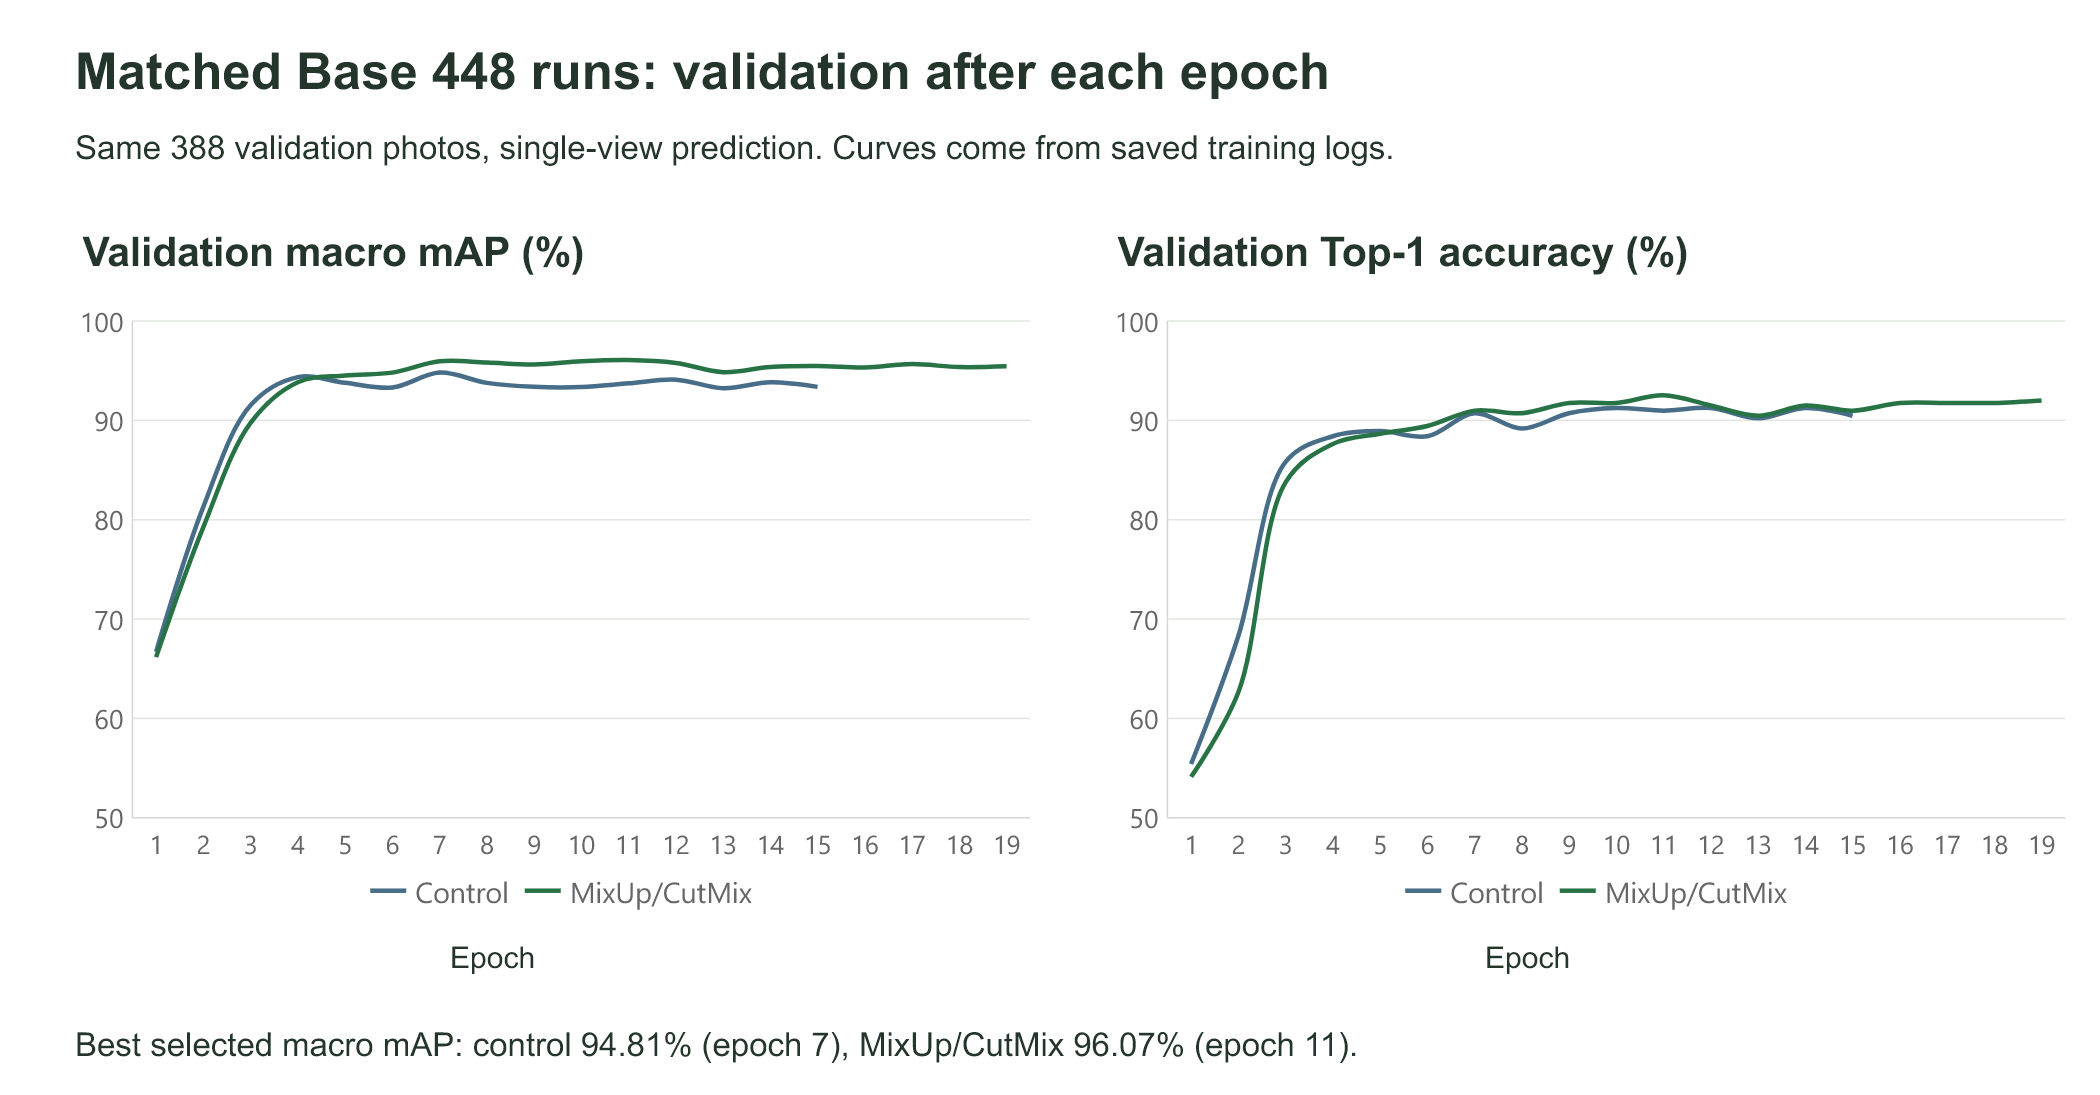

In [15]:
histories = {
    arm: pd.read_csv(EVIDENCE / arm / "training_history.csv")
    for arm in ["control", "mixup_cutmix"]
}
rows = []
for arm, result in saved_results.items():
    history = histories[arm]
    best_row = history.loc[history.val_macro_map.idxmax()]
    assert int(best_row.epoch) == result["best_epoch"]
    assert np.isclose(best_row.val_macro_map, result["normal"]["macro_map"])
    rows.append({
        "Run": arm,
        "Epochs completed": len(history),
        "Best epoch": result["best_epoch"],
        "Validation mAP (%)": round(result["normal"]["macro_map"] * 100, 2),
        "Top-1 (%)": round(result["normal"]["top1"] * 100, 2),
    })
display(pd.DataFrame(rows))
display(OutputImage(filename=str(ROOT / "training_curves.png")))


### Per-epoch validation log

    This table comes directly from the saved CSV histories. It shows validation after every epoch,
    including epochs that did not improve the checkpoint.


In [16]:
epoch_table = pd.concat(
    [history.assign(run=arm) for arm, history in histories.items()],
    ignore_index=True,
)
display(epoch_table[["run", "epoch", "train_loss", "val_macro_map", "val_top1", "val_top5"]].round(6))


,run,epoch,train_loss,val_macro_map,val_top1,val_top5
0,control,1,3.487361,0.666980,0.554124,0.899485
1,control,2,2.425167,0.812904,0.682990,0.956186
2,control,3,1.215089,0.915251,0.858247,0.989691
3,control,4,0.714377,0.943548,0.884021,0.992268
4,control,5,0.574495,0.937757,0.889175,0.992268
5,control,6,0.515959,0.933016,0.884021,0.992268
6,control,7,0.470707,0.948053,0.907216,0.994845
7,control,8,0.451070,0.937730,0.891753,0.994845
8,control,9,0.441019,0.933779,0.907216,0.992268
9,control,10,0.426080,0.933553,0.912371,0.992268


## Compare saved validation systems

    The 368-image subset excludes 20 validation images with related copies in older training history.
    These stored comparisons use the same three-view recipe. The control/mixed pair had the highest
    observed macro mAP among these comparisons. The reused subset limits confidence in the small gain.


In [17]:
systems = pd.read_csv(EVIDENCE / "validation_system_comparison_368.csv")
selected_names = [
    "MixUp/CutMix Base alone", "MixUp/CutMix + earlier Base",
    "MixUp/CutMix + newer Small", "MixUp/CutMix + clean control",
]
comparison = systems[systems.system.isin(selected_names)].copy()
comparison["system"] = comparison["system"].str.replace("newer Small", "sampling/loss Small")
display(comparison.round(6))


,system,models,macro_map,top1,top5,images
4,MixUp/CutMix Base alone,1,0.960308,0.918478,0.997283,368
5,MixUp/CutMix + clean control,2,0.964825,0.913043,0.994565,368
6,MixUp/CutMix + earlier Base,2,0.961754,0.910326,1.000000,368
7,MixUp/CutMix + sampling/loss Small,2,0.960329,0.910326,0.994565,368


## Class-level weaknesses

    Bacterial leaf spot and septoria leaf spot remained difficult. These are per-class AP values
    from the individual runs on the same 388 validation images, not accuracy percentages.


In [18]:
class_results = pd.read_csv(EVIDENCE / "validation_class_comparison.csv")
weakest = class_results.nsmallest(4, "control_normal_AP")
display(weakest[["class", "control_normal_AP", "mixup_cutmix_normal_AP"]].round(4))


,class,control_normal_AP,mixup_cutmix_normal_AP
3,bacterial_leaf_spot,0.5918,0.6417
33,septoria_leaf_spot,0.6018,0.5791
30,rust,0.7813,0.8397
15,early_blight,0.8043,0.9532


## Previously saved final report

    The model choice was fixed before this final evaluation. The historical holdout had already
    been evaluated earlier. This cell reads the saved report and displays its confusion matrix.
    It does not open test images or run inference.


,macro_map,top1,top5,images
0,0.929896,0.894061,0.993579,623


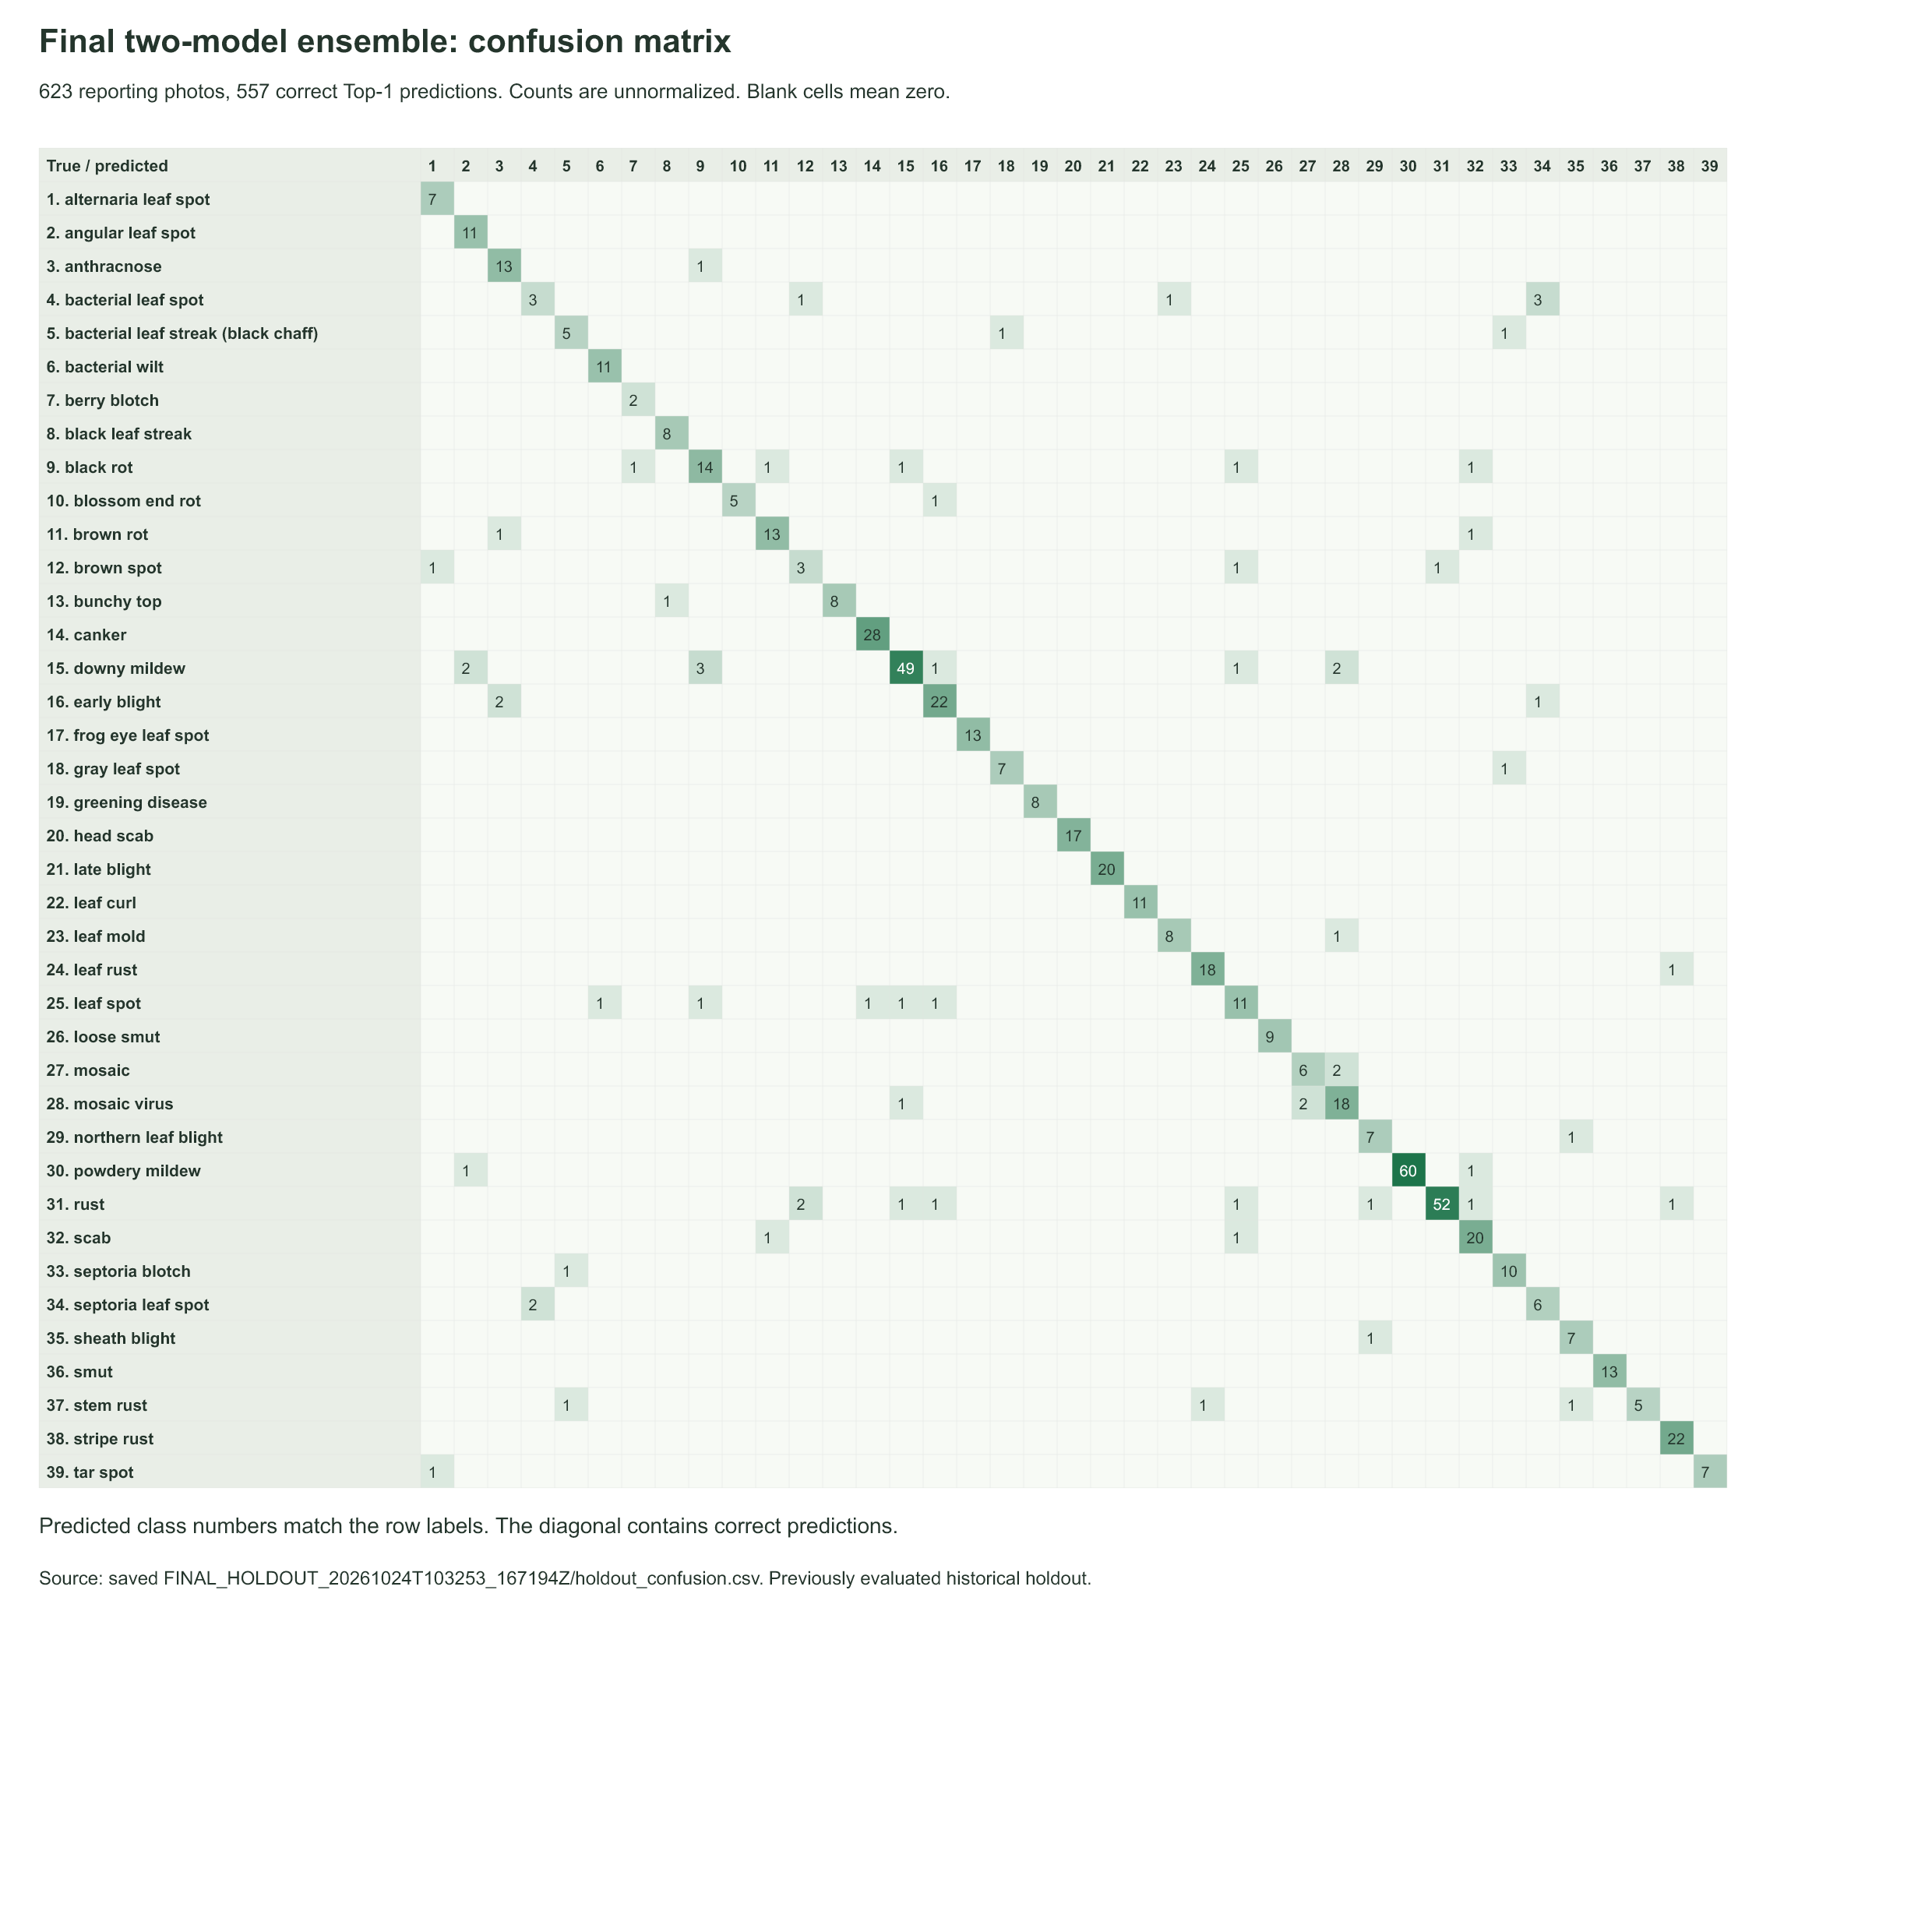

Correct first predictions: 557


In [19]:
final_report = read_report("final_reporting_result.json")
display(pd.DataFrame([final_report["score"]]).round(6))
print("Correct first predictions:", final_report["correct_top1"])
display(OutputImage(filename=str(ROOT / "confusion_matrix.png")))


Sources: [original Kaggle experiment](https://www.kaggle.com/code/armenbars/mroot-deploy),
    [EVA-02](https://arxiv.org/abs/2303.11331), [MixUp](https://arxiv.org/abs/1710.09412),
    [CutMix](https://arxiv.org/abs/1905.04899). `evidence/provenance.json` lists original file checksums.
    The training blocks are presented for review and have not been rerun for this notebook export.
